# Geneation of features

In [36]:
import glob
import re
import itertools

import matplotlib.pyplot as plt
import scipy.signal
import seaborn as sns
import numpy as np
import pandas as pd

In [37]:
import bidict

In [38]:
import pymc as pm

In [39]:
import arviz as az

In [40]:
import pytensor as pt

In [41]:
from scipy import io

In [42]:
import os

Idea: 
 - focus on a single user for now
  -  estimate parameters from the non-intensive activities time series
  - build a model to predict/impute values for the intensive activities  

- restrict to z axis?
- restrict to accelometer?

## Data etc

In [8]:
phone_acc_df = pd.read_pickle('data/phone_acc_df.pkl')
phone_gyro_df = pd.read_pickle('data/phone_gyro_df.pkl')
watch_acc_df = pd.read_pickle('data/watch_acc_df.pkl')
watch_gyro_df = pd.read_pickle('data/watch_gyro_df.pkl')

In [9]:
activity_codes = bidict.bidict({
    'A': 'walking',
    'B': 'jogging',
    'C': 'stairs',
    'D': 'sitting',
    'E': 'standing',
    'F': 'typing',
    'G': 'teeth',
    'H': 'soup',
    'I': 'chips',
    'J': 'pasta',
    'K': 'drinking',
    'L': 'sandwich',
    'M': 'kicking',
    'O': 'catch',
    'P': 'dribbling',
    'Q': 'writing',
    'R': 'clapping',
    'S': 'folding'
})

In [10]:
activity_groups = {
    "non-hand": ['walking', 'jogging', 'stairs', 'standing', "kicking"],
    "hand": ["dribbling","catch", "typing", "writing", "clapping",  "teeth", "folding"],
    "hand-eating": ["soup", "chips", "pasta", "sandwich", "drinking"]
}

In [11]:
user_id = 1610

## Auxiliary features

In [52]:
idx_eat = phone_acc_df.loc[: , 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand-eating']}) 
df_eat = phone_acc_df.loc[idx_eat]

In [53]:
idx_act = phone_acc_df.loc[:, 'ACTIVITY'].isin({activity_codes.inverse[desc] for desc in activity_groups['hand']})
df_act = phone_acc_df.loc[idx_act]

<Axes: >

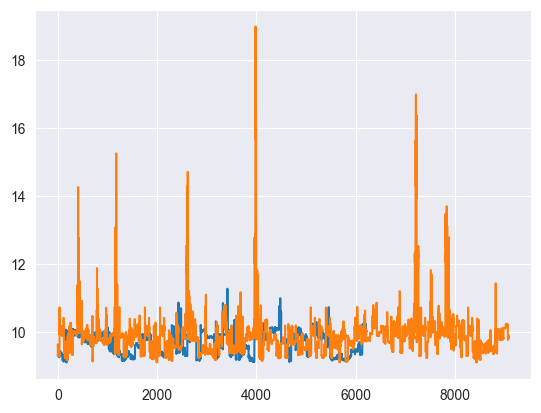

In [54]:
df_eat.reset_index()['RESULTANT'].plot()
df_act.reset_index()['RESULTANT'].plot()


In [59]:
eat_avgs  = df_eat.drop(columns="ACTIVITY").reset_index().groupby("class").mean()

`FIXME: what to do with the histogram features?`

In [48]:
eat_avgs

X0           0.297765
X1           0.159098
X2           0.068412
X3           0.118040
X4           0.158082
               ...   
YZCOS        0.191572
XYCOR       -0.045089
XZCOR        0.034044
YZCOR        0.011277
RESULTANT    9.674919
Length: 91, dtype: float64

In [17]:
scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)

(array([ 52, 141, 230, 319, 408, 497, 586]),
 {'prominences': array([0.18211, 0.18211, 0.18211, 0.18211, 0.18211, 0.18211, 0.1032 ]),
  'left_bases': array([ 32, 121, 210, 299, 388, 477, 566]),
  'right_bases': array([121, 210, 299, 388, 477, 566, 613])})

In [18]:
df_eat["RESULTANT"].iloc[scipy.signal.find_peaks(df_eat["RESULTANT"], prominence=0.1)[0]
]

class
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
1610    9.44997
Name: RESULTANT, dtype: float64

In [63]:
def find_peak_mean(column, prominence=0.1):
        return column.iloc[scipy.signal.find_peaks(column, prominence=prominence)[0]].mean()


In [89]:
eat_peak_means = df_eat.drop(columns="ACTIVITY").reset_index().groupby("class").aggregate(lambda x: find_peak_mean(x, prominence=0.05))
# eat_peak_means.head()

In [61]:
act_avgs  = df_act.drop(columns="ACTIVITY").reset_index().groupby("class").mean()

In [90]:
act_peak_means = df_act.drop(columns="ACTIVITY").reset_index().groupby("class").aggregate(lambda x: find_peak_mean(x, prominence=0.05))


## Save

In [94]:
df_eat.to_parquet("data/df_eat.parquet")

In [95]:
df_act.to_parquet("data/df_act.parquet")

In [112]:
features = pd.concat([eat_avgs, eat_peak_means, act_avgs, act_peak_means],
                   keys=["Eat_avg", "Eat_peak", "Act_avg", "Act_peak"]
                  )

In [113]:
features.to_parquet("data/features.parquet")